# Bandit Auction — Discrete Multi-Good

Two buyers, two goods, discrete types {1, 2, 3} per good (9 joint types per buyer), horizon T=5.
No closed-form benchmark for multi-good discrete setting.

Acceptance-based training with **eval IC** (oracle re-opt restarts) gating checkpoints.
Set `RUN_ENV = 'colab'` or `'local'`.

In [1]:
RUN_ENV = 'colab'   # 'colab' | 'local'
LOCAL_PROJECT_DIR = None
# LOCAL_PROJECT_DIR = r'E:\Research\code\Dynamic Mechanism Design\Bandit Auction'

In [2]:
import os, sys, subprocess

if RUN_ENV == 'colab':
    subprocess.check_call([sys.executable, '-m', 'pip', 'uninstall', '-y',
        'jax', 'jaxlib', 'jax-cuda12-plugin', 'jax-cuda12-pjrt'],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-qU',
        'jax[cuda12]', 'dm-haiku', 'optax', 'flax'])
    print('Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.')
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction')
        print(f'Working directory: {os.getcwd()}')
    except ImportError:
        print('(Drive mount skipped — restart first.)')
elif RUN_ENV == 'local':
    if LOCAL_PROJECT_DIR:
        os.chdir(LOCAL_PROJECT_DIR)
    print(f'Working directory: {os.getcwd()}')

Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction


In [3]:
import jax
import jax.numpy as jnp
import haiku as hk
import optax
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pickle, json, os

from bandit_auction.core import (
    AuctionSimulator, DiscretePolicy, build_discrete_policy_net,
)
from bandit_auction.mechanisms.network import Mechanism, build_mechanism_network
from bandit_auction.train.binary_search import (
    train_with_checkpoints, evaluate_checkpoint_list, DEFAULT_BS_CFG,
)
from bandit_auction.train.run_penalty import nested_GD_penalty
from bandit_auction.train.evaluate import eval_mechanism_multikey, print_eval_report
from bandit_auction.envs.discrete_multi import create_discrete_multi_auction

print('JAX devices:', jax.devices())

JAX devices: [CudaDevice(id=0)]


## Configuration

In [4]:
EXPERIMENT  = 'discrete_multi'
IS_DISCRETE = True
PROFIT_GOAL = 14.4    # no closed-form benchmark; set based on prior runs
SEED        = 42

cfg = {**DEFAULT_BS_CFG,
    # Training
    'lr_theta':           1e-4,
    'lr_w':               1e-3,
    'num_outer_epochs':   2000,
    'num_inner_steps':    500,
    'num_samples_train':  128,
    'alpha_base':         30.0,
    'beta_weight':        10.0,
    'pg_base':            PROFIT_GOAL,
    'print_iter':         50,
    # Checkpoint gating (training IC/IR)
    'checkpoint_thresh':  0.15,
    'checkpoint_interval': 50,
    # Eval IC (re-opt oracle)
    'ic_thresh':          0.05,
    'gap_thresh':         0.1,
    'ic_reopt_steps':     600,
    'ic_reopt_restarts':  3,
    'ic_reopt_lr':        5e-4,
    'ic_reopt_samples':   256,
    # Final eval
    'eval_num_keys':      32,
    'eval_num_samples':   256,
}
print('Config loaded. profit_goal =', PROFIT_GOAL)

Config loaded. profit_goal = 14.4


## Build Environment and Networks

In [5]:
auction = create_discrete_multi_auction(
    n_buyers=2, n_goods=2, horizon=5, discount=0.9,
    type_values_per_good=[1.0, 2.0, 3.0], allocation_cost=0.1, seed=SEED,
)
print(f'Auction: {auction.num_buyers}B x {auction.num_goods}G x T={auction.num_horizons}')
print(f'Type values per good: [1.0, 2.0, 3.0]  ({3**auction.num_goods} joint types per buyer)')

s0 = auction.get_initial_state(jax.random.PRNGKey(0))
print(f'Initial types: {s0.current_type}')

Auction: 2B x 2G x T=5
Type values per good: [1.0, 2.0, 3.0]  (9 joint types per buyer)
Initial types: [[1. 2.]
 [2. 2.]]


In [6]:
mechanism_network = build_mechanism_network()
policy_network = build_discrete_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub, hidden=128,
)

_prng = hk.PRNGSequence(SEED)
_mnet = mechanism_network
_b0   = auction.get_initial_belief_state(s0)
_mp   = _mnet.init(next(_prng), s0, jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
_pp   = policy_network.init(next(_prng), _b0, auction)
print(f'Mechanism params: {sum(p.size for p in jax.tree_util.tree_leaves(_mp)):,}')
print(f'Policy params:    {sum(p.size for p in jax.tree_util.tree_leaves(_pp)):,}')

Mechanism params: 47,029
Policy params:    18,318


## Test: Oracle Inner Loop (Maximize Cumulative Regret)

Run the inner optimization loop against a **fixed** mechanism to verify that the oracle converges and finds profitable deviations. This is a sanity check before full training.

- `TEST_MECHANISM_PARAMS = None` uses a **randomly initialized** mechanism.
- Set it to trained params (e.g. `best_mechanism_params` from a prior run) to measure how much regret a trained mechanism actually allows.

The regret curve should climb from near-0 and plateau. If it stays flat at 0 throughout, the oracle is not finding deviations — increase `ORACLE_TEST_STEPS` or check the policy initialization.

Using randomly initialized mechanism (ORACLE_MECHANISM_SEED=5376).
Restart 1/3
  step    0: regret = 0.000135
  step  100: regret = 0.133866
  step  200: regret = 0.124059
  step  300: regret = 0.137918
  step  400: regret = 0.111849
  → restart best: 0.154541
Restart 2/3
  step    0: regret = 0.000000
  step  100: regret = 0.128162
  step  200: regret = 0.124619
  step  300: regret = 0.106651
  step  400: regret = 0.114570
  → restart best: 0.155671
Restart 3/3
  step    0: regret = -0.000041
  step  100: regret = 0.129919
  step  200: regret = 0.129113
  step  300: regret = 0.120517
  step  400: regret = 0.103894
  → restart best: 0.146057


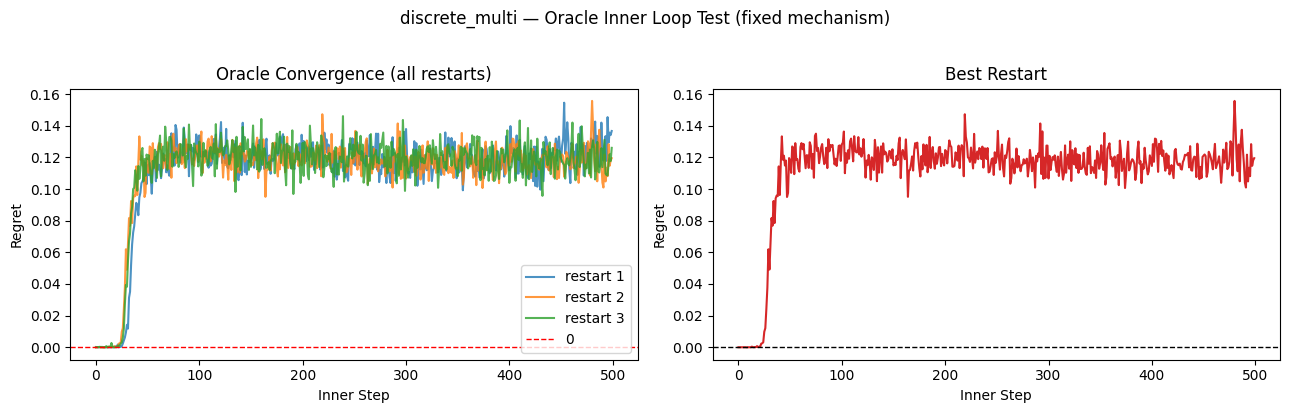


Best regret across all restarts: 0.155671
(If this stays near 0, the oracle cannot find deviations — mechanism may already be approximately IC, or oracle needs more steps/LR.)


In [ ]:
# ---- Oracle test configuration ----
ORACLE_TEST_STEPS    = 500    # inner gradient-ascent steps (matches num_inner_steps)
ORACLE_TEST_RESTARTS = 3      # independent random restarts
ORACLE_TEST_LR       = cfg['lr_w']  # reuse training inner LR
ORACLE_TEST_SAMPLES  = 128     # MC samples per regret estimate
TEST_MECHANISM_PARAMS = None  # None → random init; or set to best_mechanism_params

# Change this seed to test a different random mechanism.
ORACLE_MECHANISM_SEED = 5376

# ---- Build oracle networks ----
_oracle_mnet = mechanism_network
_oracle_pnet = build_discrete_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub, hidden=128,
)

# ---- Initialize test mechanism params ----
_oracle_prng = hk.PRNGSequence(ORACLE_MECHANISM_SEED)
_oracle_s0   = auction.get_initial_state(next(_oracle_prng))
if TEST_MECHANISM_PARAMS is None:
    _test_mparams = _oracle_mnet.init(
        next(_oracle_prng), _oracle_s0,
        jnp.zeros((auction.num_buyers, auction.num_goods)), auction,
    )
    print(f'Using randomly initialized mechanism (ORACLE_MECHANISM_SEED={ORACLE_MECHANISM_SEED}).')
else:
    _test_mparams = TEST_MECHANISM_PARAMS
    print('Using provided mechanism params.')
_test_mechanism = Mechanism(_oracle_mnet, _test_mparams)

# ---- JIT-compiled oracle step ----
_oracle_opt = optax.adam(ORACLE_TEST_LR)

@jax.jit
def _oracle_step(policy_params, w_opt_state, key):
    _reg, _grad = jax.value_and_grad(
        lambda pp: AuctionSimulator.estimate_cumulative_regret(
            auction, _test_mechanism,
            DiscretePolicy(_oracle_pnet, pp),
            ORACLE_TEST_SAMPLES, key,
            auction.get_next_belief_state_discrete,
        )
    )(policy_params)
    _grad_asc = jax.tree_util.tree_map(lambda g: -g, _grad)
    _upd, w_opt_state = _oracle_opt.update(_grad_asc, w_opt_state, policy_params)
    policy_params = optax.apply_updates(policy_params, _upd)
    return _reg, policy_params, w_opt_state

# ---- Run oracle for each restart ----
_oracle_curves   = []
_oracle_best_reg = -float('inf')
_oracle_key_base = ORACLE_MECHANISM_SEED * 1_000_000

for _restart in range(ORACLE_TEST_RESTARTS):
    _b0  = auction.get_initial_belief_state(_oracle_s0)
    _pp  = _oracle_pnet.init(next(_oracle_prng), _b0, auction)
    _ws  = _oracle_opt.init(_pp)
    _curve = []
    print(f'Restart {_restart+1}/{ORACLE_TEST_RESTARTS}')
    for _step in range(ORACLE_TEST_STEPS):
        _key = jax.random.PRNGKey(_oracle_key_base + _restart * 100_000 + _step)
        _reg, _pp, _ws = _oracle_step(_pp, _ws, _key)
        _curve.append(float(_reg))
        if _step % 100 == 0:
            print(f'  step {_step:4d}: regret = {float(_reg):.6f}')
    _oracle_curves.append(_curve)
    _oracle_best_reg = max(_oracle_best_reg, max(_curve))
    print(f'  → restart best: {max(_curve):.6f}')

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for _r, _c in enumerate(_oracle_curves):
    axes[0].plot(_c, alpha=0.8, label=f'restart {_r+1}')
axes[0].axhline(0, color='red', linestyle='--', lw=1, label='0')
axes[0].set_xlabel('Inner Step'); axes[0].set_ylabel('Regret')
axes[0].set_title('Oracle Convergence (all restarts)'); axes[0].legend()
_best_c = _oracle_curves[max(range(len(_oracle_curves)), key=lambda r: max(_oracle_curves[r]))]
axes[1].plot(_best_c, color='tab:red')
axes[1].axhline(0, color='k', linestyle='--', lw=1)
axes[1].set_xlabel('Inner Step'); axes[1].set_ylabel('Regret')
axes[1].set_title('Best Restart')
plt.suptitle(f'{EXPERIMENT} — Oracle Inner Loop Test (fixed mechanism)', y=1.02)
plt.tight_layout(); plt.show()
print(f'\nBest regret across all restarts: {_oracle_best_reg:.6f}')
print('(If this stays near 0, the oracle cannot find deviations — '
      'mechanism may already be approximately IC, or oracle needs more steps/LR.)')

# Acceptance

## Training with Checkpoint Recording

`train_with_checkpoints` runs nested GD and records every checkpoint where training IC ≤ `checkpoint_thresh` and training IR ≤ `checkpoint_thresh`. The final epoch is always included as a candidate.

**Note:** Checkpoints are gated on *training* losses (cheap). The next cell evaluates each checkpoint with the tighter *eval* IC criterion (oracle re-opt restarts).

In [ ]:
checkpoints, logs = train_with_checkpoints(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)
print(f'\nTraining complete. Candidate checkpoints: {len(checkpoints)}')

  [train] profit_goal=14.400  alpha=30.00  lr_theta=1.0e-04  lr_w=1.0e-03
=== Outer Epoch 0 (39.4s) ===
  oracle regret:  1.174913
  reg:            1.164708   reg_+=1.164708
  gap:            13.940804   gap_+=13.940804
  ir_loss:        0.000000
  total loss:     48.882050
=== Outer Epoch 50 (110.1s) ===
  oracle regret:  -0.009410
  reg:            -0.004290   reg_+=0.000000
  gap:            14.414187   gap_+=14.414187
  ir_loss:        0.000000
  total loss:     14.414187
=== Outer Epoch 100 (180.4s) ===
  oracle regret:  0.007104
  reg:            0.001671   reg_+=0.001671
  gap:            14.042068   gap_+=14.042068
  ir_loss:        0.000000
  total loss:     14.092211
=== Outer Epoch 150 (251.2s) ===
  oracle regret:  -0.003502
  reg:            -0.009685   reg_+=0.000000
  gap:            13.514933   gap_+=13.514933
  ir_loss:        0.000000
  total loss:     13.514933
=== Outer Epoch 200 (321.8s) ===
  oracle regret:  0.017581
  reg:            -0.014889   reg_+=0.000000
 

In [ ]:
_train_state_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}/training_state'
os.makedirs(_train_state_dir, exist_ok=True)
with open(f'{_train_state_dir}/checkpoints.pkl', 'wb') as f:
    pickle.dump(checkpoints, f)
with open(f'{_train_state_dir}/logs.pkl', 'wb') as f:
    pickle.dump(logs, f)
print(f'Saved {len(checkpoints)} checkpoints to {_train_state_dir}/')


Saved 40 checkpoints to outputs/discrete_multi/acceptance/seed42/training_state/


## Checkpoint Evaluation — Eval IC + IR with Oracle Re-opt

For each candidate checkpoint, the oracle is re-optimized from scratch (`ic_reopt_restarts` × `ic_reopt_steps` gradient ascent steps). A checkpoint **PASS**es if:
- `max(IC_reopt, IC_eval) ≤ ic_thresh` (= 0.05)
- `profit_goal − revenue_eval ≤ gap_thresh` (= 0.1)
- `IR_eval ≤ ir_thresh` (= 0.05)

Checkpoints are sorted: feasible first, then by descending revenue.

In [ ]:
_train_state_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}/training_state'
with open(f'{_train_state_dir}/checkpoints.pkl', 'rb') as f:
    checkpoints = pickle.load(f)
with open(f'{_train_state_dir}/logs.pkl', 'rb') as f:
    logs = pickle.load(f)
print(f'Loaded {len(checkpoints)} checkpoints from {_train_state_dir}/')
print(f'  Training curves available: {list(logs.keys())}')


Loaded 40 checkpoints from outputs/discrete_multi/acceptance/seed42/training_state/
  Training curves available: ['loss', 'reg', 'gap', 'ir', 'reg_plus', 'gap_plus', 'oracle_reg_last', 'checkpoint_mech', 'mechanism_params', 'policy_params']


In [ ]:
eval_results = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)

feasible = [r for r in eval_results if r['feasible']]
print(f'\n{len(feasible)} / {len(eval_results)} checkpoints PASS eval (IC + IR + gap).')
if feasible:
    best = feasible[0]
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Best: epoch={best["epoch"]}  rev={best["revenue_eval"]:.4f}  '
          f'IC_reopt={best["regret_reopt"]:.4f}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')
else:
    print('No feasible checkpoint. Using checkpoint with lowest eval IC.')
    best = min(eval_results, key=lambda r: r['regret_eval'])
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Lowest IC: epoch={best["epoch"]}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')

    [ckpt 1/40] epoch=  50 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch=  50  rev=-0.0196  gap=14.4196  IC_reopt=0.0153  IC_eval=-0.0094  IR_eval=0.0000
    [ckpt 2/40] epoch= 100 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 100  rev=0.3651  gap=14.0349  IC_reopt=0.0111  IC_eval=-0.0154  IR_eval=0.0000
    [ckpt 3/40] epoch= 150 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 150  rev=0.8931  gap=13.5069  IC_reopt=0.0113  IC_eval=-0.0105  IR_eval=0.0000
    [ckpt 4/40] epoch= 200 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 200  rev=1.8534  gap=12.5466  IC_reopt=0.0028  IC_eval=-0.0212  IR_eval=0.0000
    [ckpt 5/40] epoch= 250 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 250  rev=3.0223  gap=11.3777  IC_reopt=0.0274  IC_eval=0.0045  IR_eval=0.0000
    [ckpt 6/40] epoch= 300 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 300  rev=5.1129  gap=9.

## Checkpoint Summary Table

In [ ]:
print(f'\n{"="*80}')
print(f'  {EXPERIMENT} — Checkpoint Evaluation Summary  (profit_goal={PROFIT_GOAL})')
print(f'{"="*80}')
print(f'  {"Epoch":>6} | {"Rev":>7} | {"Gap":>6} | {"IC_reopt":>8} | {"IC_eval":>8} | {"IR_eval":>7} | Result')
print('  ' + '-'*70)
for r in sorted(eval_results, key=lambda x: x['epoch']):
    _flag = 'PASS ★' if r['feasible'] else 'fail  '
    print(f'  {r["epoch"]:>6} | {r["revenue_eval"]:>7.4f} | '
          f'{PROFIT_GOAL - r["revenue_eval"]:>6.4f} | '
          f'{r["regret_reopt"]:>8.4f} | '
          f'{r["regret_eval"]:>8.4f} | '
          f'{r["ir_loss_eval"]:>7.4f} | {_flag}')


  discrete_multi — Checkpoint Evaluation Summary  (profit_goal=14.4)
   Epoch |     Rev |    Gap | IC_reopt |  IC_eval | IR_eval | Result
  ----------------------------------------------------------------------
      50 | -0.0196 | 14.4196 |   0.0153 |  -0.0094 |  0.0000 | fail  
     100 |  0.3651 | 14.0349 |   0.0111 |  -0.0154 |  0.0000 | fail  
     150 |  0.8931 | 13.5069 |   0.0113 |  -0.0105 |  0.0000 | fail  
     200 |  1.8534 | 12.5466 |   0.0028 |  -0.0212 |  0.0000 | fail  
     250 |  3.0223 | 11.3777 |   0.0274 |   0.0045 |  0.0000 | fail  
     300 |  5.1129 | 9.2871 |   0.0140 |  -0.0085 |  0.0000 | fail  
     350 |  9.3698 | 5.0302 |   0.0326 |  -0.0006 |  0.0235 | fail  
     400 | 11.1621 | 3.2379 |   0.0117 |  -0.0118 |  0.1102 | fail  
     450 | 11.4782 | 2.9218 |   0.0226 |  -0.0129 |  0.0942 | fail  
     500 | 11.6858 | 2.7142 |   0.0172 |  -0.0561 |  0.0841 | fail  
     550 | 12.1851 | 2.2149 |   0.0218 |  -0.0105 |  0.1072 | fail  
     600 | 12.2335 | 2.1

## Convergence Curves with Checkpoint Markers

- **Green ★** = PASS (eval IC ≤ 0.05, IR ≤ 0.05, revenue gap ≤ 0.1)
- **Red ✗** = fail
- Dashed green vertical = selected best checkpoint

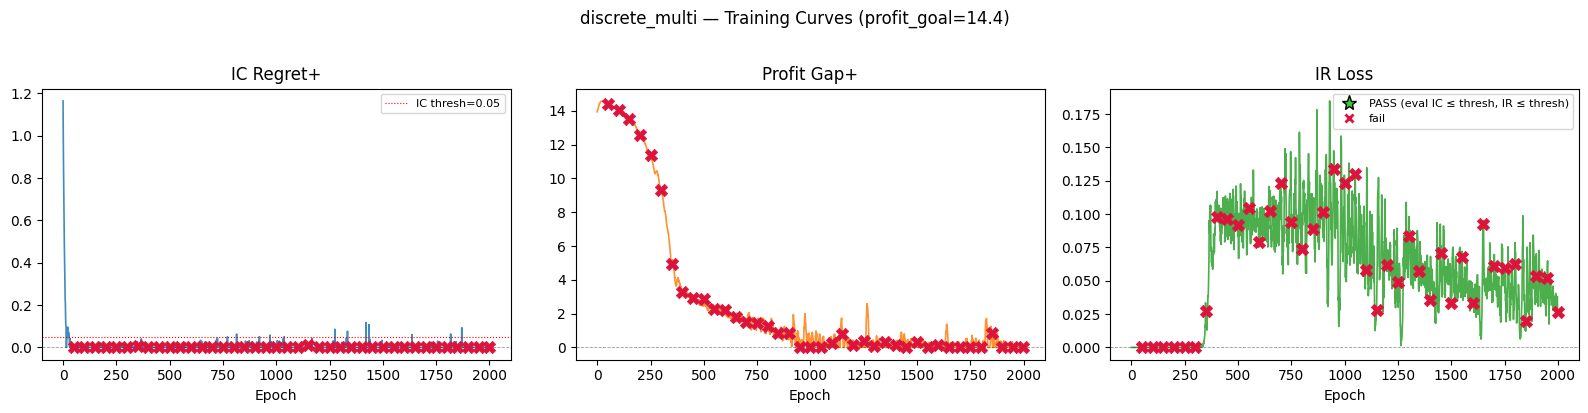

Oracle regret (last inner step): -0.1050


In [ ]:
_ckpt_by_epoch = {r['epoch']: r for r in eval_results}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
_curves = [logs['reg_plus'], logs['gap_plus'], logs['ir']]
_titles = ['IC Regret+', 'Profit Gap+', 'IR Loss']
_cols   = ['tab:blue', 'tab:orange', 'tab:green']

for ax, curve, title, col in zip(axes, _curves, _titles, _cols):
    ax.plot(curve, color=col, alpha=0.85, lw=1.2)
    ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
    ax.set_xlabel('Epoch'); ax.set_title(title)

axes[0].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
axes[0].legend(fontsize=8)

for epoch, r in sorted(_ckpt_by_epoch.items()):
    _pass = r['feasible']
    _col  = 'limegreen' if _pass else 'crimson'
    _mk   = '*' if _pass else 'X'
    _ms   = 180 if _pass else 80
    for i, (ax, curve) in enumerate(zip(axes, _curves)):
        _y = curve[min(epoch, len(curve) - 1)]
        ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                   edgecolors='black' if _pass else _col, linewidths=0.5)

_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson',
           markersize=9, label='fail'),
]
axes[2].legend(handles=_legend_elems, loc='upper right', fontsize=8)

if feasible:
    for ax in axes:
        ax.axvline(best['epoch'], color='limegreen', lw=1.5, linestyle='--', alpha=0.6)

plt.suptitle(f'{EXPERIMENT} — Training Curves (profit_goal={PROFIT_GOAL})', y=1.02)
plt.tight_layout(); plt.show()

print(f'Oracle regret (last inner step): {logs["oracle_reg_last"][-1]:.4f}')

## Final Evaluation on Best Checkpoint

In [ ]:
final_eval_keys = jax.random.split(jax.random.PRNGKey(88888), cfg['eval_num_keys'])
final_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys,
    policy_network=policy_network,
    policy_params=best_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results, prefix=f'{EXPERIMENT} best checkpoint (epoch {best["epoch"]}): ')


  discrete_multi best checkpoint (epoch 1400): Evaluation Report
  profit                   : 14.4032 ± 0.0730  [14.2537, 14.5089]
  gap plus                 : 0.0293 ± 0.0428  [0.0000, 0.1463]
  buyer surplus            : 3.6964 ± 0.0679  [3.5682, 3.7982]
  ir loss                  : 0.0478 ± 0.0092  [0.0259, 0.0665]
  ic regret                : -0.1109 ± 0.0736



## Save Outputs

In [ ]:
save_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
os.makedirs(save_dir, exist_ok=True)

with open(f'{save_dir}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_mechanism_params, f)
with open(f'{save_dir}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_policy_params, f)

_summary = {
    'experiment':   EXPERIMENT,
    'profit_goal':  PROFIT_GOAL,
    'best_epoch':   int(best['epoch']),
    'revenue_eval': float(best['revenue_eval']),
    'regret_reopt': float(best['regret_reopt']),
    'regret_eval':  float(best['regret_eval']),
    'ir_loss_eval': float(best['ir_loss_eval']),
    'feasible':     bool(best['feasible']),
    'num_pass':     len(feasible),
    'num_candidates': len(eval_results),
    'cfg':          {k: v for k, v in cfg.items() if not callable(v)},
    'final_eval':   {k: v for k, v in final_results.items() if isinstance(v, dict)},
}
with open(f'{save_dir}/summary.json', 'w') as f:
    json.dump(_summary, f, indent=2)

_curves_out = {
    'reg_plus': [float(x) for x in logs['reg_plus']],
    'gap_plus': [float(x) for x in logs['gap_plus']],
    'ir':       [float(x) for x in logs['ir']],
    'reg':      [float(x) for x in logs['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir}/training_curves.json', 'w') as f:
    json.dump(_curves_out, f, indent=2)

print(f'Saved to: {save_dir}/')
print(f'  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json')

Saved to: outputs/discrete_multi/acceptance/seed42/
  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json


# Penalty

Penalty: alpha=15.0, beta=15.0
=== Outer Epoch 0 (37.9s) ===
  oracle regret (train):  1.174913
  reg (in loss):          1.164708   reg_+=1.164708
  profit:                 0.459196
  ir_loss:                0.000000
  total loss:             17.011427
=== Outer Epoch 50 (112.6s) ===
  oracle regret (train):  -0.002444
  reg (in loss):          0.003760   reg_+=0.003760
  profit:                 0.135854
  ir_loss:                0.000000
  total loss:             -0.079455
=== Outer Epoch 100 (187.7s) ===
  oracle regret (train):  -0.003053
  reg (in loss):          0.000279   reg_+=0.000279
  profit:                 0.863351
  ir_loss:                0.000000
  total loss:             -0.859165
=== Outer Epoch 150 (262.8s) ===
  oracle regret (train):  -0.006935
  reg (in loss):          -0.019415   reg_+=0.000000
  profit:                 2.231898
  ir_loss:                0.000000
  total loss:             -2.231898
=== Outer Epoch 200 (338.4s) ===
  oracle regret (train):  -0.040

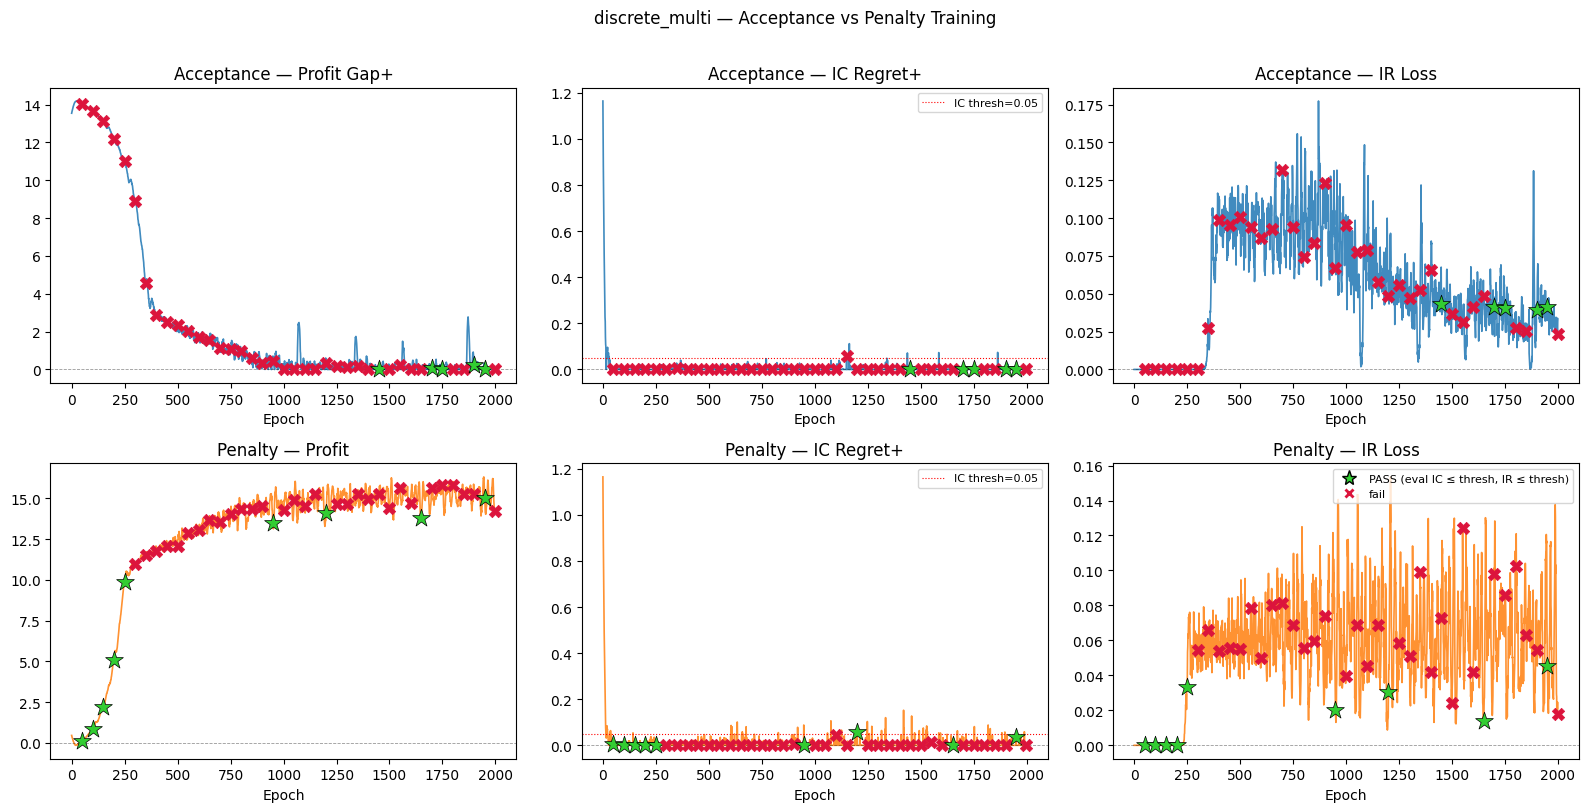


  discrete_multi penalty best (epoch 1950): Evaluation Report
  profit                   : 14.5427 ± 0.0719  [14.4034, 14.7208]
  gap plus                 : 0.0000 ± 0.0000  [0.0000, 0.0000]
  buyer surplus            : 4.5729 ± 0.0717  [4.4116, 4.7957]
  ir loss                  : 0.0283 ± 0.0059  [0.0175, 0.0423]
  ic regret                : -0.0959 ± 0.0485

Penalty outputs saved to: outputs/discrete_multi/penalty/seed42/


In [ ]:
# ---- Penalty training configuration ----
# Set alpha and beta independently from the acceptance method — tune as needed.
PENALTY_ALPHA = 15.0   # IC penalty weight
PENALTY_BETA  = 15.0   # IR penalty weight
print(f'Penalty: alpha={PENALTY_ALPHA}, beta={PENALTY_BETA}')

# ---- Train ----
logs_penalty = nested_GD_penalty(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    num_outer_epochs=cfg['num_outer_epochs'],
    lr_theta=cfg['lr_theta'],
    num_inner_steps=cfg['num_inner_steps'],
    lr_w=cfg['lr_w'],
    num_samples_train=cfg['num_samples_train'],
    alpha_weight=PENALTY_ALPHA,
    beta_weight=PENALTY_BETA,
    print_iter=cfg['print_iter'],
    checkpoint_thresh=cfg['checkpoint_thresh'],
    checkpoint_interval=cfg['checkpoint_interval'],
    is_discrete=IS_DISCRETE,
    seed=SEED,
)
checkpoints_penalty = logs_penalty['checkpoint_mech'] + [{
    'epoch':            cfg['num_outer_epochs'] - 1,
    'reg_train':        logs_penalty['reg'][-1],
    'ir_train':         logs_penalty['ir'][-1],
    'profit_train':     logs_penalty['profit'][-1],
    'mechanism_params': logs_penalty['mechanism_params'],
    'policy_params':    logs_penalty['policy_params'],
}]
print(f'\nPenalty training complete. Candidate checkpoints: {len(checkpoints_penalty)}')

# ---- Checkpoint evaluation ----
# For penalty method: gate on eval IC + eval IR only — no profit-gap constraint.
cfg_penalty = {**cfg, 'gap_thresh': float('inf')}
eval_results_penalty = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints_penalty,
    profit_goal=0.0,
    cfg=cfg_penalty,
    is_discrete=IS_DISCRETE,
    seed=SEED + 1,
    verbose=True,
)
feasible_penalty = [r for r in eval_results_penalty if r['feasible']]
print(f'\n{len(feasible_penalty)} / {len(eval_results_penalty)} penalty checkpoints PASS eval (IC + IR).')
if feasible_penalty:
    best_penalty = feasible_penalty[0]
    print(f'Best: epoch={best_penalty["epoch"]}  rev={best_penalty["revenue_eval"]:.4f}  '
          f'IC_reopt={best_penalty["regret_reopt"]:.4f}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
else:
    print('No feasible penalty checkpoint. Using checkpoint with lowest eval IC.')
    best_penalty = min(eval_results_penalty, key=lambda r: r['regret_eval'])
    print(f'Lowest IC: epoch={best_penalty["epoch"]}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
best_penalty_mechanism_params = best_penalty['mechanism_params']
best_penalty_policy_params    = best_penalty.get('reopt_policy_params', best_penalty['policy_params'])

# ---- Convergence curves — Acceptance (top) vs Penalty (bottom) ----
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
_ckpt_by_epoch_penalty = {r['epoch']: r for r in eval_results_penalty}
_ckpt_by_epoch_accept  = {r['epoch']: r for r in eval_results}

for (row_axes, row_curves, row_titles, row_col, ckpts_dict) in [
    (axes[0],
     [logs['gap_plus'], logs['reg_plus'], logs['ir']],
     ['Acceptance — Profit Gap+', 'Acceptance — IC Regret+', 'Acceptance — IR Loss'],
     'tab:blue', _ckpt_by_epoch_accept),
    (axes[1],
     [logs_penalty['profit'], logs_penalty['reg_plus'], logs_penalty['ir']],
     ['Penalty — Profit', 'Penalty — IC Regret+', 'Penalty — IR Loss'],
     'tab:orange', _ckpt_by_epoch_penalty),
]:
    for ax, curve, title in zip(row_axes, row_curves, row_titles):
        ax.plot(curve, color=row_col, lw=1.2, alpha=0.85)
        ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
        ax.set_xlabel('Epoch'); ax.set_title(title)
    row_axes[1].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
    row_axes[1].legend(fontsize=8)
    for epoch, r in sorted(ckpts_dict.items()):
        _col = 'limegreen' if r['feasible'] else 'crimson'
        _mk  = '*' if r['feasible'] else 'X'
        _ms  = 180 if r['feasible'] else 80
        for ax, curve in zip(row_axes, row_curves):
            _y = curve[min(epoch, len(curve) - 1)]
            ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                       edgecolors='black' if r['feasible'] else _col, linewidths=0.5)

_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson', markersize=9, label='fail'),
]
axes[1][2].legend(handles=_legend_elems, loc='upper right', fontsize=8)
plt.suptitle(f'{EXPERIMENT} — Acceptance vs Penalty Training', y=1.01)
plt.tight_layout(); plt.show()

# ---- Final evaluation ----
final_eval_keys_penalty = jax.random.split(jax.random.PRNGKey(99999), cfg['eval_num_keys'])
final_results_penalty = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys_penalty,
    policy_network=policy_network,
    policy_params=best_penalty_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results_penalty, prefix=f'{EXPERIMENT} penalty best (epoch {best_penalty["epoch"]}): ')

# ---- Save ----
save_dir_penalty = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
os.makedirs(save_dir_penalty, exist_ok=True)
with open(f'{save_dir_penalty}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_mechanism_params, f)
with open(f'{save_dir_penalty}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_policy_params, f)
_summary_penalty = {
    'experiment': EXPERIMENT, 'method': 'penalty',
    'penalty_alpha': PENALTY_ALPHA, 'penalty_beta': PENALTY_BETA,
    'best_epoch': int(best_penalty['epoch']),
    'revenue_eval': float(best_penalty['revenue_eval']),
    'regret_reopt': float(best_penalty['regret_reopt']),
    'regret_eval':  float(best_penalty['regret_eval']),
    'ir_loss_eval': float(best_penalty['ir_loss_eval']),
    'feasible':     bool(best_penalty['feasible']),
    'num_pass':     len(feasible_penalty),
    'num_candidates': len(eval_results_penalty),
}
with open(f'{save_dir_penalty}/summary.json', 'w') as f:
    json.dump(_summary_penalty, f, indent=2)
_curves_pen_out = {
    'profit':   [float(x) for x in logs_penalty['profit']],
    'reg_plus': [float(x) for x in logs_penalty['reg_plus']],
    'ir':       [float(x) for x in logs_penalty['ir']],
    'reg':      [float(x) for x in logs_penalty['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results_penalty, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir_penalty}/training_curves.json', 'w') as f:
    json.dump(_curves_pen_out, f, indent=2)
print(f'Penalty outputs saved to: {save_dir_penalty}/')

In [ ]:
print(f'\nPenalty training complete. Candidate checkpoints: {len(checkpoints_penalty)}')
_penalty_state_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}/training_state'
os.makedirs(_penalty_state_dir, exist_ok=True)
with open(f'{_penalty_state_dir}/checkpoints_penalty.pkl', 'wb') as f:
    pickle.dump(checkpoints_penalty, f)
with open(f'{_penalty_state_dir}/logs_penalty.pkl', 'wb') as f:
    pickle.dump(logs_penalty, f)
print(f'Saved {len(checkpoints_penalty)} penalty checkpoints to {_penalty_state_dir}/')



Penalty training complete. Candidate checkpoints: 40
Saved 40 penalty checkpoints to outputs/discrete_multi/penalty/seed42/training_state/


## Reload & Evaluate Saved Results

Load mechanism and policy params from disk and re-evaluate without rerunning training.

**Prerequisite:** Run cells through "Build Environment and Networks" (cells 1–8) so that `auction`, `mechanism_network`, `policy_network`, `cfg`, and `PROFIT_GOAL` are in scope. Training cells are not required.

In [7]:
# ---- Load acceptance results ----
_acc_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
with open(f'{_acc_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_mechanism_params = pickle.load(f)
with open(f'{_acc_dir}/policy_params.pkl', 'rb') as f:
    loaded_policy_params = pickle.load(f)
with open(f'{_acc_dir}/summary.json') as f:
    loaded_summary = json.load(f)

print(f'Acceptance — loaded from: {_acc_dir}')
print(f'  epoch={loaded_summary["best_epoch"]}  revenue={loaded_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_summary["feasible"]}  IC_eval={loaded_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_summary["ir_loss_eval"]:.4f}')

_reload_keys = jax.random.split(jax.random.PRNGKey(55555), cfg['eval_num_keys'])
loaded_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_keys,
    policy_network=policy_network,
    policy_params=loaded_policy_params,
    is_discrete=IS_DISCRETE,
    reopt_steps=600,               # re-optimise oracle from scratch
    reopt_restarts=3,
    reopt_lr=5e-4,
    reopt_samples=128,
)
print_eval_report(loaded_results, prefix=f'{EXPERIMENT} [loaded acceptance]: ')

# ---- Load penalty results ----
_pen_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
with open(f'{_pen_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_penalty_mechanism_params = pickle.load(f)
with open(f'{_pen_dir}/policy_params.pkl', 'rb') as f:
    loaded_penalty_policy_params = pickle.load(f)
with open(f'{_pen_dir}/summary.json') as f:
    loaded_penalty_summary = json.load(f)

print(f'\nPenalty — loaded from: {_pen_dir}')
print(f'  epoch={loaded_penalty_summary["best_epoch"]}  revenue={loaded_penalty_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_penalty_summary["feasible"]}  IC_eval={loaded_penalty_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_penalty_summary["ir_loss_eval"]:.4f}')

_reload_pen_keys = jax.random.split(jax.random.PRNGKey(66666), cfg['eval_num_keys'])
loaded_penalty_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_pen_keys,
    policy_network=policy_network,
    policy_params=loaded_penalty_policy_params,
    is_discrete=IS_DISCRETE,
      reopt_steps=600,               # re-optimise oracle from scratch
    reopt_restarts=3,
    reopt_lr=5e-4,
    reopt_samples=128,
)
print_eval_report(loaded_penalty_results, prefix=f'{EXPERIMENT} [loaded penalty]: ')

Acceptance — loaded from: outputs/discrete_multi/acceptance/seed42
  epoch=1400  revenue=14.3777  feasible=False  IC_eval=-0.1446  IR_eval=0.0509

  discrete_multi [loaded acceptance]: Evaluation Report
  profit                   : 14.3707 ± 0.0635  [14.2637, 14.5293]
  gap plus                 : 0.0437 ± 0.0443  [0.0000, 0.1363]
  buyer surplus            : 3.6972 ± 0.0763  [3.5493, 3.8682]
  ir loss                  : 0.0529 ± 0.0101  [0.0290, 0.0679]
  ic regret                : 0.0000 ± 0.0000  (reopt peak: 0.0925)


Penalty — loaded from: outputs/discrete_multi/penalty/seed42
  epoch=1950  revenue=14.5172  feasible=True  IC_eval=-0.0907  IR_eval=0.0308

  discrete_multi [loaded penalty]: Evaluation Report
  profit                   : 14.5402 ± 0.0577  [14.4045, 14.6484]
  gap plus                 : 0.0000 ± 0.0000  [0.0000, 0.0000]
  buyer surplus            : 4.5766 ± 0.0856  [4.4284, 4.7831]
  ir loss                  : 0.0256 ± 0.0069  [0.0126, 0.0415]
  ic regret              